In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#import cufflinks as cf
#from plotly.offline import iplot
df = pd.read_csv("/kaggle/input/datasets/sakinofbd/bangladesh-aqi-dataset-20002025/AQI Bangladesh.csv")

print("Shape:", df.shape)

Shape: (1048551, 13)


In [2]:
df.head()

,city_id,city_name,lat,lon,datetime,pm10,pm2_5,carbon_monoxide,carbon_dioxide,nitrogen_dioxide,sulphur_dioxide,ozone,aqi
0,7701354,Azimpur,23.7298,90.3854,2022-08-05T00:00,25.0,16.7,252.0,NaN,18.6,5.2,13.0,50.0
1,7701354,Azimpur,23.7298,90.3854,2022-08-05T01:00,18.5,12.3,249.0,NaN,18.5,5.7,19.0,50.0
2,7701354,Azimpur,23.7298,90.3854,2022-08-05T02:00,16.1,10.9,244.0,NaN,18.4,6.5,27.0,51.0
3,7701354,Azimpur,23.7298,90.3854,2022-08-05T03:00,15.4,10.3,233.0,NaN,17.2,6.9,39.0,51.0
4,7701354,Azimpur,23.7298,90.3854,2022-08-05T04:00,16.8,11.3,217.0,NaN,14.8,6.2,51.0,51.0


In [3]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048551 entries, 0 to 1048550
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   city_id           1048551 non-null  int64  
 1   city_name         1048551 non-null  object 
 2   lat               1048551 non-null  float64
 3   lon               1048551 non-null  float64
 4   datetime          1048551 non-null  object 
 5   pm10              1048551 non-null  float64
 6   pm2_5             1048551 non-null  float64
 7   carbon_monoxide   1048551 non-null  float64
 8   carbon_dioxide    274224 non-null   float64
 9   nitrogen_dioxide  1048551 non-null  float64
 10  sulphur_dioxide   1048551 non-null  float64
 11  ozone             1048551 non-null  float64
 12  aqi               1047855 non-null  float64
dtypes: float64(10), int64(1), object(2)
memory usage: 104.0+ MB


city_id                  0
city_name                0
lat                      0
lon                      0
datetime                 0
pm10                     0
pm2_5                    0
carbon_monoxide          0
carbon_dioxide      774327
nitrogen_dioxide         0
sulphur_dioxide          0
ozone                    0
aqi                    696
dtype: int64

Here, The dataset contains missing values in two columns. The "carbon_dioxide" column has 774,327 missing (NaN) entries which represents approximately 74% of the data. So, we will ignore that column. The aqi column has only 696 missing values (0.07%). So, we decided to remove that rows where aqi is (NaN). 

In [4]:

df = df.drop(columns=["city_id", "city_name"])
df = df.drop(columns=["carbon_dioxide"])
df = df.dropna(subset=['aqi'])

print(df['aqi'].isnull().sum())

0


In [5]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 1047855 entries, 0 to 1048550
Data columns (total 10 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   lat               1047855 non-null  float64
 1   lon               1047855 non-null  float64
 2   datetime          1047855 non-null  object 
 3   pm10              1047855 non-null  float64
 4   pm2_5             1047855 non-null  float64
 5   carbon_monoxide   1047855 non-null  float64
 6   nitrogen_dioxide  1047855 non-null  float64
 7   sulphur_dioxide   1047855 non-null  float64
 8   ozone             1047855 non-null  float64
 9   aqi               1047855 non-null  float64
dtypes: float64(9), object(1)
memory usage: 87.9+ MB


lat                 0
lon                 0
datetime            0
pm10                0
pm2_5               0
carbon_monoxide     0
nitrogen_dioxide    0
sulphur_dioxide     0
ozone               0
aqi                 0
dtype: int64

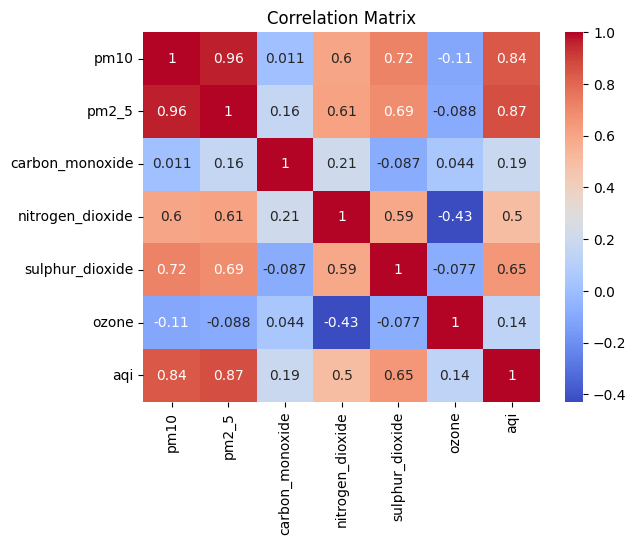

In [6]:
corr = df[["pm10","pm2_5","carbon_monoxide","nitrogen_dioxide","sulphur_dioxide","ozone","aqi"]].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

# Splitting the dataset into test and train


In [7]:

n = len(df)

shuffle = np.random.permutation(n)

split = int(0.7 * n)

train_IDs = shuffle[:split]
test_IDS= shuffle[split:]

AQI_TRAIN = df.iloc[train_IDs]
AQI_TEST = df.iloc[test_IDS]

AQI_TRAIN = AQI_TRAIN.reset_index(drop=True)
AQI_TEST = AQI_TEST.reset_index(drop=True)
print("Train shape:", AQI_TRAIN.shape)
print("Test shape:", AQI_TEST.shape)


Train shape: (733498, 10)
Test shape: (314357, 10)


In [8]:
print(AQI_TRAIN.head())
AQI_TRAIN.duplicated().sum()


        lat       lon          datetime  pm10  pm2_5  carbon_monoxide  \
0  22.68759  90.64403  2023-06-01T20:00  37.7   23.3            262.0   
1  24.43200  90.55850  2025-06-18T05:00   6.9    6.7            187.0   
2  23.01472  89.43936  2024-07-25T16:00  26.5   17.8            336.0   
3  24.21623  90.95002  2025-01-20T09:00  63.1   62.4            500.0   
4  22.48898  90.06273  2022-09-21T00:00  27.6   15.9            147.0   

   nitrogen_dioxide  sulphur_dioxide  ozone    aqi  
0               0.8              3.2   82.0   82.0  
1               8.4              5.8   78.0   42.0  
2              19.9              2.6   39.0   57.0  
3               2.7              8.6  176.0  160.0  
4               1.4              1.0   75.0   48.0  


np.int64(0)

In [9]:
print(AQI_TEST.head())
AQI_TEST.duplicated().sum()

        lat       lon          datetime        pm10       pm2_5  \
0  23.71040  90.40744  2011-07-15T02:00  146.475976   75.488748   
1  21.43973  92.00955  2023-07-21T02:00    1.200000    0.900000   
2  23.59311  90.14251  2023-09-05T02:00   68.200000   47.400000   
3  23.71040  90.40744  2020-06-08T19:00  248.484477  132.349442   
4  24.07821  89.63262  2025-03-15T23:00   41.100000   39.600000   

   carbon_monoxide  nitrogen_dioxide  sulphur_dioxide       ozone         aqi  
0         0.888145         17.252863        12.690967   43.307205  160.531479  
1       108.000000          1.200000         0.300000   53.000000   23.000000  
2       503.000000         19.600000        16.200000  103.000000   98.000000  
3         1.649059         36.533569        24.274126   65.726817  190.489696  
4       620.000000          7.500000         4.300000   48.000000  151.000000  


np.int64(0)

# Selecting Features with Strong Positive Correlation


In [10]:
features = ['pm2_5', 'pm10','sulphur_dioxide']  
m_train = AQI_TRAIN[features].values   
n_train = AQI_TRAIN['aqi'].values      


m_test  = AQI_TEST[features].values
n_test  = AQI_TEST['aqi'].values

print('m_train shape:', m_train.shape)
print('n_train shape:', n_train.shape)
print('m_test shape:', m_test.shape)
print('n_test shape:', n_test.shape)

m_train shape: (733498, 3)
n_train shape: (733498,)
m_test shape: (314357, 3)
n_test shape: (314357,)


# Adding the bias column


In [11]:



ones_train = np.ones((m_train.shape[0], 1))
ones_test  = np.ones((m_test.shape[0], 1))


A_train = np.hstack([ones_train, m_train])
A_test  = np.hstack([ones_test, m_test])


print('A_train shape:', A_train.shape)   
print('A_test shape:', A_test.shape)

print('First row of A_train:', A_train[0])

A_train shape: (733498, 4)
A_test shape: (314357, 4)
First row of A_train: [ 1.  23.3 37.7  3.2]


# Normal Equation


In [12]:
AT      = A_train.T                         
ATA     = AT @ A_train                       
ATA_inv = np.linalg.inv(ATA)                
ATy     = AT @ n_train                      

beta = ATA_inv @ ATy                       

print('Intercept (beta_0):', round(beta[0], 2))
print('Coefficient for pm2_5:', round(beta[1], 2))
print('Coefficient for pm10:', round(beta[2], 2))
print('Coefficient for so2:', round(beta[3], 2))

Intercept (beta_0): 57.95
Coefficient for pm2_5: 1.1
Coefficient for pm10: -0.07
Coefficient for so2: 0.65


# Making prediction on trained data

In [13]:
n_train_predictions = A_train @ beta

for i in range(5):
    print(f'Actual: {n_train[i]:.0f}   Predicted: {n_train_predictions[i]:.0f}')

Actual: 82   Predicted: 83
Actual: 42   Predicted: 69
Actual: 57   Predicted: 77
Actual: 160   Predicted: 128
Actual: 48   Predicted: 74


# Calculatting MSE

In [14]:
# Predictions
n_test_predictions = A_test @ beta

# Errors
errors = n_test - n_test_predictions

# MSE and RMSE
squared = errors ** 2
mse = squared.mean()
rmse = mse ** 0.5

# MAE
mae = abs(errors).mean()

# R² 
ss_res = (errors ** 2).sum()
ss_tot = ((n_test - n_test.mean()) ** 2).sum()
r2 = 1 - (ss_res / ss_tot)

# Print results
print('Test MSE: ', round(mse, 2))
print('Test RMSE:', round(rmse, 2))
print('Test MAE: ', round(mae, 2))
print('Test R2:  ', round(r2, 4))

Test MSE:  648.56
Test RMSE: 25.47
Test MAE:  20.65
Test R2:   0.766


# Visualise prediction vs actual

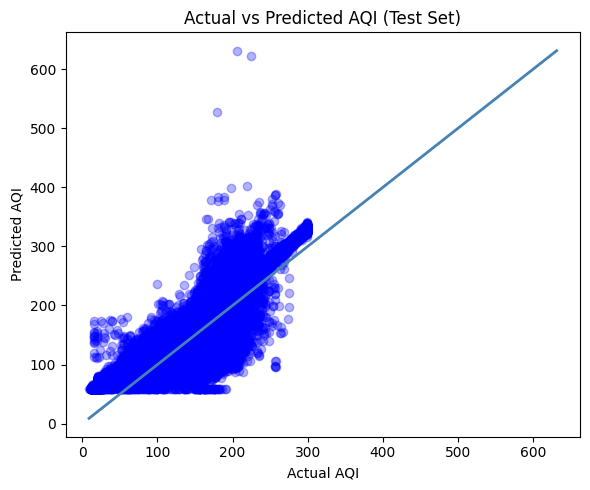

In [15]:
plt.figure(figsize=(6, 5))
plt.scatter(n_test, n_test_predictions, alpha=0.3, color='blue')


min_val = min(n_test.min(), n_test_predictions.min())
max_val = max(n_test.max(), n_test_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], color='steelblue', linewidth=2)

plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.title('Actual vs Predicted AQI (Test Set)')
plt.tight_layout()
plt.show()

In [16]:
X_train = AQI_TRAIN[['pm2_5', 'pm10','sulphur_dioxide']].values
y_train = AQI_TRAIN['aqi'].values

X_test  = AQI_TEST[['pm2_5', 'pm10','sulphur_dioxide']].values
y_test  = AQI_TEST['aqi'].values

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

# add bias column
A_train_norm = np.hstack([np.ones((X_train_norm.shape[0], 1)), X_train_norm])
A_test_norm  = np.hstack([np.ones((X_test_norm.shape[0], 1)), X_test_norm])

print(A_train_norm.shape)

(733498, 4)


In [18]:
beta_gd = np.zeros(A_train_norm.shape[1])  # [b0, b1, b2]

alpha = 0.01        # learning rate (you can tune 0.001–0.05)
iterations = 15000  # more steps for stability
n = len(y_train)

mse_history = []

In [19]:
for i in range(iterations):

    # predictions
    y_hat = A_train_norm @ beta_gd

    # error
    error = y_hat - y_train

    # gradient
    gradient = (A_train_norm.T @ error) / n

    # update weights
    beta_gd = beta_gd - alpha * gradient

    # track loss
    mse_history.append((error ** 2).mean())

    # optional print
    if i % 200 == 0:
        print(f"Iteration {i}, MSE: {mse_history[-1]:.2f}")

Iteration 0, MSE: 16016.36
Iteration 200, MSE: 939.72
Iteration 400, MSE: 690.68
Iteration 600, MSE: 679.66
Iteration 800, MSE: 675.11
Iteration 1000, MSE: 671.55
Iteration 1200, MSE: 668.55
Iteration 1400, MSE: 665.97
Iteration 1600, MSE: 663.74
Iteration 1800, MSE: 661.82
Iteration 2000, MSE: 660.16
Iteration 2200, MSE: 658.72
Iteration 2400, MSE: 657.48
Iteration 2600, MSE: 656.41
Iteration 2800, MSE: 655.48
Iteration 3000, MSE: 654.68
Iteration 3200, MSE: 653.99
Iteration 3400, MSE: 653.39
Iteration 3600, MSE: 652.88
Iteration 3800, MSE: 652.43
Iteration 4000, MSE: 652.05
Iteration 4200, MSE: 651.71
Iteration 4400, MSE: 651.43
Iteration 4600, MSE: 651.18
Iteration 4800, MSE: 650.96
Iteration 5000, MSE: 650.78
Iteration 5200, MSE: 650.62
Iteration 5400, MSE: 650.48
Iteration 5600, MSE: 650.36
Iteration 5800, MSE: 650.25
Iteration 6000, MSE: 650.17
Iteration 6200, MSE: 650.09
Iteration 6400, MSE: 650.02
Iteration 6600, MSE: 649.96
Iteration 6800, MSE: 649.91
Iteration 7000, MSE: 649.

In [20]:
print("Gradient Descent Parameters:")
print("Intercept:", beta_gd[0])
print("pm2_5 coef:", beta_gd[1])
print("pm10  coef:", beta_gd[2])
print("so2  coef:", beta_gd[3])


Gradient Descent Parameters:
Intercept: 115.09697280792136
pm2_5 coef: 45.988808384379546
pm10  coef: -4.476917801830653
so2  coef: 6.072008169222418


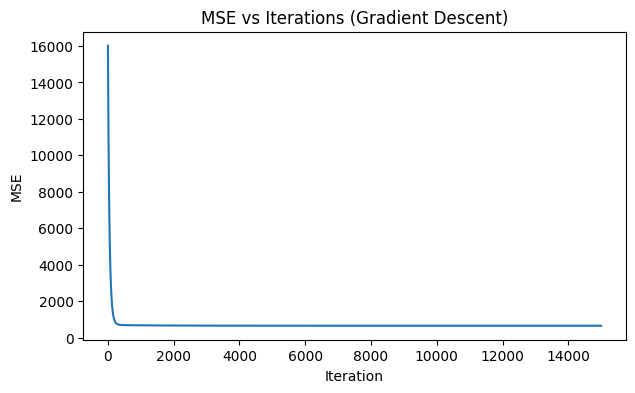

In [21]:
plt.figure(figsize=(7,4))
plt.plot(mse_history)
plt.title("MSE vs Iterations (Gradient Descent)")
plt.xlabel("Iteration")
plt.ylabel("MSE")
plt.show()

In [22]:
y_pred_gd = A_test_norm @ beta_gd

errors = y_test - y_pred_gd

mse  = (errors ** 2).mean()
rmse = mse ** 0.5
mae  = np.abs(errors).mean()

ss_res = (errors ** 2).sum()
ss_tot = ((y_test - y_test.mean()) ** 2).sum()
r2 = 1 - ss_res / ss_tot

print("GD Test MSE :", round(mse, 2))
print("GD Test RMSE:", round(rmse, 2))
print("GD Test MAE :", round(mae, 2))
print("GD Test R2  :", round(r2, 4))

GD Test MSE : 648.56
GD Test RMSE: 25.47
GD Test MAE : 20.65
GD Test R2  : 0.766
